# 4 · From theory and simulation to the real Tumbller

**Tumbller balance course — notebook 4 of 4.**

Notebooks 1–3 lived in Python. This one walks across to the Arduino Nano on the
robot: where each equation sits in the firmware, how to measure the numbers the
model needs, how to get data *out* of the robot, and how to tune it with the
simulation at your side instead of by trial and error alone.

**The plan:**
1. Find the theory in the firmware — `balanceCar()` line by line.
2. Translate units: what does `kp_balance = 55` mean physically?
3. Measure your robot (five small experiments) and build *your* `tb.Params`.
4. Calibrate the sensors.
5. Add telemetry and live tuning to the firmware; record data.
6. Compare the recording with the simulation, close the loop on the model.
7. Tune on the hardware — procedure, safety, troubleshooting.

Honesty note: the Arduino code in `arduino/` is written against the stock
firmware in your `Arduino/TumbllerComplete` folder and passes a C++ syntax check,
but **I could not compile it for the Nano or run it on a robot.** Treat the
first upload as a test. All "measurement" data in this notebook is *synthetic* —
generated by the simulator to demonstrate the analysis — and marked as such.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
import tumbller as tb
from tumbller import SERIES, INK, INK2, GRID, tidy
tb.use_style()
p = tb.Params()

import os
os.makedirs("data", exist_ok=True)
g = tb.STOCK

## 4.1 · Where the theory lives in the firmware

Everything that matters is in `BalanceCar.h`, in the function `balanceCar()`,
which `MsTimer2` calls every 5 ms. Stripped of the motor-pin handling, it does
this (firmware lines on the left, course vocabulary on the right):

```cpp
void balanceCar()                                   // called every 5 ms by a timer interrupt
{
  // --- SENSORS ---------------------------------------------------------------
  encoder_left_pulse_num_speed += pwm_left < 0 ? -encoder_count_left_a   // encoder edges since last
                                               :  encoder_count_left_a;  // tick; sign GUESSED from PWM
  mpu.getMotion6(&ax, &ay, &az, &gx, &gy, &gz);                          // raw accelerometer + gyro
  kalmanfilter.Angle(ax, ay, az, gx, gy, gz, dt, Q_angle, Q_gyro, R_angle, C_0, K1);
  kalmanfilter_angle = kalmanfilter.angle;                               // tilt estimate  (nb 2.7)

  // --- BALANCE LOOP: PD on tilt, every tick ------------------------------- (nb 2.1)
  double balance_control_output = kp_balance * (kalmanfilter_angle - angle_zero)
                                + kd_balance * (kalmanfilter.Gyro_x - angular_velocity_zero);

  // --- SPEED LOOP: PI on wheel speed, every 8th tick = 40 ms -------------- (nb 2.3-2.5)
  speed_control_period_count++;
  if (speed_control_period_count >= 8)
  {
    speed_control_period_count = 0;
    double car_speed = (encoder_left_pulse_num_speed + encoder_right_pulse_num_speed) * 0.5;
    encoder_left_pulse_num_speed = 0;
    encoder_right_pulse_num_speed = 0;
    speed_filter = speed_filter_old * 0.7 + car_speed * 0.3;            // the low-pass that makes
    speed_filter_old = speed_filter;                                     //   the cascade work
    car_speed_integeral += speed_filter;                                 // integral = distance
    car_speed_integeral += -setting_car_speed;                           // drive command enters here
    car_speed_integeral = constrain(car_speed_integeral, -3000, 3000);   // anti-windup clamp
    speed_control_output = -kp_speed * speed_filter - ki_speed * car_speed_integeral;
    rotation_control_output = setting_turn_speed + kd_turn * kalmanfilter.Gyro_z;   // turning
  }

  // --- SUM, LIMIT, OUTPUT -----------------------------------------------------
  pwm_left  = balance_control_output - speed_control_output - rotation_control_output;
  pwm_right = balance_control_output - speed_control_output + rotation_control_output;
  pwm_left  = constrain(pwm_left, -255, 255);                            // saturation (nb 3.6)
  pwm_right = constrain(pwm_right, -255, 255);
  if (... kalmanfilter_angle < balance_angle_min || balance_angle_max < kalmanfilter_angle)
    motion_mode = STOP;                                                  // fallen: beyond +-22 deg
  ...                                                                    // sign -> AIN1/BIN1, |pwm| -> analogWrite
}
```

`tb.FirmwareController.tick()` is this function in Python — open `tumbller.py`
and read the two side by side.

| course | firmware | where |
|---|---|---|
| tilt $\theta$ | `kalmanfilter_angle` [deg] | `KalmanFilter.cpp`: `atan2(ay, az) * 57.3`, then Kalman |
| tilt rate $\dot\theta$ | `kalmanfilter.Gyro_x` [°/s] | `(gx - 128.1) / 131` — raw gyro minus a fixed offset |
| wheel speed | `speed_filter` [counts / 40 ms] | encoder edges, both wheels averaged, low-passed |
| distance | `car_speed_integeral` [counts] | sum of the above, clamped to ±3000 |
| command $u$ | `pwm_left`, `pwm_right` | −255…255, sign → direction pin |
| loop period | `MsTimer2::set(5, balanceCar)` | `carInitialize()` |
| gains | `kp_balance, kd_balance, kp_speed, ki_speed` | top of `BalanceCar.h` |
| zero angle | `angle_zero` | top of `BalanceCar.h` (stock: 0) |

Three firmware details that the theory did not prepare you for:

- **The encoders have no direction.** Only channel A of each encoder is
  connected (pins 2 and 4). The firmware *assumes* the wheel turns the way it is
  being driven. Usually true; wrong whenever the wheel is pushed against the motor.
- **A third loop exists**: `kd_turn * Gyro_z` damps rotation about the vertical
  axis and `setting_turn_speed` steers. It only makes the two PWM values differ
  and does not interact with balancing, which is why the course ignores it.
- **Start-up logic** (`Tumbller.ino`): after power-on the robot waits 2 s, and
  only starts balancing if it is within ±22° of upright. Beyond ±22° it switches
  the motors off — your safety net while tuning.

## 4.2 · Units: what do the firmware gains mean physically?

The firmware works in degrees, encoder counts and PWM counts. Converting to SI
makes the gains comparable with the physics:

In [2]:
def explain_gains(p, g):
    D2R = np.pi / 180
    Ts = p.dt * p.speed_div
    k_theta = g.kp_balance / D2R * p.k_m                   # Nm per rad of tilt
    c_theta = g.kd_balance / D2R * p.k_m                   # Nm per rad/s
    counts_per_mps = p.N / p.r * Ts                        # counts per 40 ms at 1 m/s
    print(f"kp_balance = {g.kp_balance:6.2f} PWM/deg        -> {k_theta:5.2f} Nm/rad    "
          f"(gravity: {p.m_body*tb.G*p.l:.2f} Nm/rad to beat)")
    print(f"kd_balance = {g.kd_balance:6.2f} PWM/(deg/s)    -> {c_theta*1e3:5.1f} mNm s/rad "
          f"(motor back-EMF: {p.b_m*1e3:.1f} mNm s/rad, acting on wheel speed)")
    print(f"kp_speed   = {g.kp_speed:6.2f} PWM/count      -> {g.kp_speed*counts_per_mps:5.0f} PWM per m/s  "
          f"(1 m/s = {counts_per_mps:.0f} counts per 40 ms)")
    print(f"ki_speed   = {g.ki_speed:6.2f} PWM/count      -> {g.ki_speed*p.N/p.r/100:5.1f} PWM per cm of travel")
    print(f"full PWM 255 = {p.stall_total:.2f} Nm at standstill;  PWM saturates at "
          f"{255/g.kp_balance:.1f} deg of tilt error (balance term alone)")

explain_gains(p, g)

kp_balance =  55.00 PWM/deg        ->  8.07 Nm/rad    (gravity: 0.31 Nm/rad to beat)
kd_balance =   0.75 PWM/(deg/s)    -> 110.1 mNm s/rad (motor back-EMF: 26.0 mNm s/rad, acting on wheel speed)
kp_speed   =  10.00 PWM/count      ->  1482 PWM per m/s  (1 m/s = 148 counts per 40 ms)
ki_speed   =   0.26 PWM/count      ->   9.6 PWM per cm of travel
full PWM 255 = 0.65 Nm at standstill;  PWM saturates at 4.6 deg of tilt error (balance term alone)


Useful intuition from these numbers: the balance loop is a spring some 25 times
stiffer than gravity; the gyro term is a damper of the same order as the
motor's own back-EMF damping (the two act on different speeds — tilt rate and
wheel speed — so they are not directly comparable, but neither is negligible);
and the balance term alone saturates the motors at about 4–5° of tilt error —
beyond that, more gain changes nothing.

Because gains carry units, they depend on the hardware: the same `kp_speed`
means twice as much on a robot whose encoder delivers twice the counts, and
every gain means 15 % less on a tired battery.

## 4.3 · Measuring your robot

Five experiments, in order of payoff. Each ends in a number for `tb.Params`.
Tools: kitchen scale, ruler or caliper, phone stopwatch, a piece of string.

### E1 · Encoder counts per wheel revolution *(2 minutes, most important)*

Upload `arduino/Motor_Step_Test/Motor_Step_Test.ino` (robot on its side or on a
stand — this sketch does not balance). Serial Monitor at **115200 baud**, line
ending "Newline". Send `z`, turn the **left** wheel by hand exactly 10 turns
(a piece of tape on the tyre helps), send `c`.

The datasheet in your tutorial folder says "Double hall switch 26 Pulse
output" and a 1:30 gearbox, which leaves several readings open — 13 or 26 pulses
per motor revolution, times two edges, times 30. The count settles it.

In [3]:
edges_after_10_turns = 7800          # <-- YOUR NUMBER (this one is a placeholder)
counts_per_rev = edges_after_10_turns / 10
print(f"counts_per_rev = {counts_per_rev:.0f}")
print(f"one count = {360/counts_per_rev:.2f} deg of wheel = {2*np.pi*p.r/counts_per_rev*1e3:.2f} mm of travel")
print(f"at 0.1 m/s the firmware sees {0.1/(2*np.pi*p.r)*counts_per_rev*0.005:.1f} edges per 5 ms tick, "
      f"{0.1/(2*np.pi*p.r)*counts_per_rev*0.04:.0f} per 40 ms frame")

counts_per_rev = 780
one count = 0.46 deg of wheel = 0.27 mm of travel
at 0.1 m/s the firmware sees 1.9 edges per 5 ms tick, 15 per 40 ms frame


The last line is the practical reason for the slow speed loop (notebook 2.8):
at walking pace a 5 ms tick sees only one or two edges — far too coarse to
differentiate. Forty milliseconds and a filter make a usable speed signal.

### E2 · Masses and wheel radius *(5 minutes)*

- Weigh the complete robot, then one wheel (they pull off the motor shafts).
- Wheel radius: roll the robot 10 wheel turns along a ruler; $r = d / (20\pi)$.
  Better than measuring the diameter, because it includes tyre squish under load.

### E3 · Height of the centre of mass *(5 minutes)*

Lay the robot (wheels on) across the edge of a ruler or a pencil, body
horizontal, and shift it until it balances. The balance point is the CoM of the
*whole* robot; measure its distance $l_{tot}$ from the axle. The wheels' own CoM
is on the axle, so the body CoM is a little further out:

$$l = l_{tot}\,\frac{m_{tot}}{m_{tot} - m_{wheels}}$$

### E4 · Body inertia with a pendulum test *(10 minutes)*

Hang the robot from a thin string loop or over a nail/rod through the top of the
frame so that it can swing freely in its pitch plane. Measure the distance $d$
from that pivot to the CoM (you know the CoM from E3). Let it swing by a few
degrees and time 10 periods.

A physical pendulum has $T = 2\pi\sqrt{I_{pivot}/(m\,g\,d)}$, so

$$I_{pivot} = \frac{m\,g\,d\,T^2}{4\pi^2}, \qquad I_{cm} = I_{pivot} - m\,d^2 \quad\text{(parallel-axis theorem)}$$

Do it with the wheels **off**, so that $m$ and $I$ are those of the body alone.

In [4]:
# ---- YOUR NUMBERS (placeholders: they belong to the synthetic example robot used in E5) ----
m_total   = 0.990      # kg   complete robot                     (E2)
m_wheel   = 0.035      # kg   one wheel                          (E2)
roll_dist = 2.105      # m    travelled in 10 wheel turns        (E2)
l_total   = 0.0446     # m    axle -> balance point, wheels on   (E3)
d_pivot   = 0.110      # m    pivot -> body CoM, wheels off      (E4)
T_10      = 7.39       # s    time for 10 swings                 (E4)
# ------------------------------------------------------------------------
m_wheels = 2 * m_wheel
m_body = m_total - m_wheels
r = roll_dist / (20 * np.pi)
l = l_total * m_total / m_body
T = T_10 / 10
I_pivot = m_body * tb.G * d_pivot * T**2 / (4 * np.pi**2)
I_body = I_pivot - m_body * d_pivot**2
print(f"m_body = {m_body:.3f} kg   r = {r*1e3:.1f} mm   l = {l*1e3:.1f} mm")
print(f"I_pivot = {I_pivot*1e3:.2f} g m^2  ->  I_body = {I_body*1e3:.2f} g m^2 about the CoM")
print(f"radius of gyration = {np.sqrt(I_body/m_body)*1e3:.0f} mm  (sanity: must be well inside the robot's size)")

m_body = 0.920 kg   r = 33.5 mm   l = 48.0 mm
I_pivot = 13.73 g m^2  ->  I_body = 2.60 g m^2 about the CoM
radius of gyration = 53 mm  (sanity: must be well inside the robot's size)


Sanity checks: $I_{body}$ must come out positive, and the radius of gyration
should be a few centimetres. $I_{body}$ is the difference of two similar
numbers, so it is sensitive to $d$ and $T$ — time 10 swings twice.

### E5 · Motor constants from a step test *(15 minutes)*

Robot on a stand, wheels free, `Motor_Step_Test` still loaded. Send `g`: the
sketch applies PWM steps of 60, 120, 180 and 240 and prints `ms,pwm,count` every
10 ms (plus the battery voltage). Record it:

```
python tools/tumbller_logger.py --port <your port> --baud 115200 --send g --seconds 8 --out data/motor_step.csv
```

With the wheels in the air the motor equation of notebook 1 reduces to
$I_{free}\,\dot\omega = k_m u - b_m\,\omega - \tau_{fric}$, which gives two things:

- **steady-state speed vs PWM** is a straight line: slope $k_m/b_m$ (no-load speed
  per PWM count), and its zero crossing is the **dead band** — the PWM needed to move at all;
- **the rise** is an exponential with time constant $\tau = I_{free}/b_m$, which
  reveals the rotor inertia.

The cell below first creates a *synthetic* recording (from a "true robot" that
differs from the course defaults: heavier, higher centre of mass, slower motors,
some gearbox friction) so that the analysis can run. With real data,
skip that cell.

In [5]:
# SYNTHETIC stand-in for a real recording - skip this cell when you have data/motor_step.csv
truth = p.with_(m_body=0.92, l=0.048, I_body=2.6e-3, I_rotor=9.5e-4, w0_rated=33.0,
                tau_coulomb=0.035, v_batt=7.8)

def fake_motor_step(q, path, seed=3):
    rng = np.random.default_rng(seed)
    I_free = q.I_wheels + q.I_rotor
    w = phi = 0.0
    rows, t = [], 0.0
    seq = [(0.2, 0)] + [s for u in (60, 120, 180, 240) for s in ((0.7, u), (0.5, 0))]
    for dur, u in seq:
        for _ in range(int(dur / 0.010)):
            rows.append((round(t * 1000), u, int(phi * q.N + rng.uniform(0, 1))))
            for _ in range(20):                                   # 0.5 ms Euler steps
                tau = q.k_m * u - q.b_m * w - q.tau_coulomb * np.tanh(w / 0.5)
                if u == 0 and abs(w) < 0.05:
                    tau = -w * 0.5                                # stuck
                w += tau / I_free * 0.0005
                phi += w * 0.0005
            t += 0.010
    with open(path, "w") as f:
        f.write(f"# SYNTHETIC DATA from the simulator - not a measurement\n# battery [V]: {q.v_batt}\nms,pwm,count\n")
        f.writelines(f"{a},{b},{c}\n" for a, b, c in rows)

fake_motor_step(truth, "data/motor_step.csv")

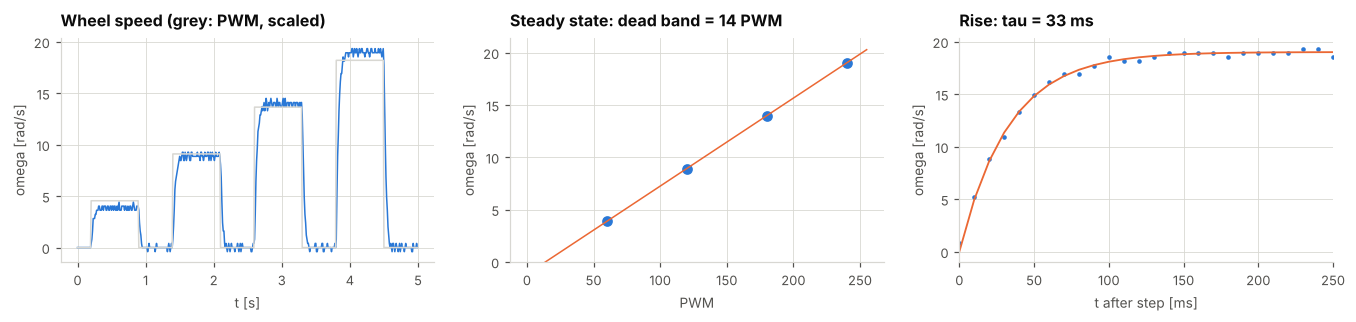

no-load speed per PWM  84.2 mrad/s   ->  w0_rated = 33.0 rad/s at 12 V (datasheet: 37.7)
back-EMF damping b_m   29.7 mNm s/rad
dead band              14 PWM  ->  friction torque 35 mNm
I_free = tau * b_m     0.98 g m^2  ->  I_rotor = 0.94 g m^2


In [6]:
from scipy.optimize import curve_fit

v_batt_measured = 7.8                 # <-- from the "# battery [V]" line of your recording
cpr = counts_per_rev                  # from E1

log = tb.load_log("data/motor_step.csv")
t, u, cnt = log["t"], log["pwm"], log["count"]
w = np.gradient(cnt, t) * 2 * np.pi / cpr                 # wheel speed [rad/s]

# steady-state speed of each step = mean over its last 0.25 s
levels, w_ss = [], []
for lev in sorted(set(u[u > 0])):
    idx = np.nonzero(u == lev)[0]
    levels.append(lev); w_ss.append(w[idx[-25:]].mean())
slope, icpt = np.polyfit(levels, w_ss, 1)
deadband = -icpt / slope

# time constant from the rise of the largest step
idx = np.nonzero(u == levels[-1])[0]
tt = t[idx] - t[idx[0]]
rise = lambda tt, tau, wss: wss * (1 - np.exp(-tt / tau))
(tau_fit, wss_fit), _ = curve_fit(rise, tt, w[idx], p0=(0.03, w_ss[-1]))

fig, axs = plt.subplots(1, 3, figsize=(12.5, 3))
axs[0].plot(t, w, lw=1); axs[0].plot(t, u / 255 * max(w), lw=1, color=GRID)
tidy(axs[0], "Wheel speed (grey: PWM, scaled)", "t [s]", "omega [rad/s]")
axs[1].plot(levels, w_ss, "o"); xs = np.array([0, 255]); axs[1].plot(xs, slope * xs + icpt, lw=1)
axs[1].set_ylim(0, None)
tidy(axs[1], f"Steady state: dead band = {deadband:.0f} PWM", "PWM", "omega [rad/s]")
axs[2].plot(tt * 1e3, w[idx], ".", ms=4); axs[2].plot(tt * 1e3, rise(tt, tau_fit, wss_fit), lw=1.2)
axs[2].set_xlim(0, 250)
tidy(axs[2], f"Rise: tau = {tau_fit*1e3:.0f} ms", "t after step [ms]", "omega [rad/s]")
plt.tight_layout(); plt.show()

# turn the fit into model parameters.  Absolute torque cannot be measured this way:
# we keep the datasheet stall torque and scale it with the measured voltage.
k_m = 2 * p.stall_rated * v_batt_measured / p.v_rated / 255
b_m = k_m / slope
w0_rated = 255 * slope * p.v_rated / v_batt_measured
I_free = tau_fit * b_m
I_rotor = I_free - p.I_wheels
tau_coulomb = deadband * k_m
print(f"no-load speed per PWM  {slope*1e3:.1f} mrad/s   ->  w0_rated = {w0_rated:.1f} rad/s at 12 V "
      f"(datasheet: {p.w0_rated})")
print(f"back-EMF damping b_m   {b_m*1e3:.1f} mNm s/rad")
print(f"dead band              {deadband:.0f} PWM  ->  friction torque {tau_coulomb*1e3:.0f} mNm")
print(f"I_free = tau * b_m     {I_free*1e3:.2f} g m^2  ->  I_rotor = {I_rotor*1e3:.2f} g m^2")

In this synthetic example the analysis recovers the values the "true robot" was
generated with (`w0_rated` 33, `I_rotor` 0.95 g m², friction 35 mNm) to within a
few percent — the method works. With your real recording, check that the
steady-state points really lie on a line and that the rise looks exponential;
if not, the simple motor model is the thing to question.

**What this test cannot give** is the absolute torque scale (`stall_rated`): that
needs a force measurement. A simple one: clamp the robot, wind a string around a
wheel, pull a kitchen scale with a low PWM (30–60, for a second or two only —
stalled motors get hot) and compute torque = force × radius.

### Your robot as a `Params` object

Collect the results. From here on, use `MY` instead of `p`:

In [7]:
MY = tb.Params(
    m_body=m_body, l=l, I_body=I_body,                 # E2, E3, E4
    m_wheels=m_wheels, r=r,                            # E2
    I_wheels=0.5 * m_wheels * r**2,                    # solid-disc estimate
    counts_per_rev=cpr,                                # E1
    w0_rated=w0_rated, I_rotor=I_rotor,                # E5
    tau_coulomb=tau_coulomb, v_batt=v_batt_measured,   # E5
)
print(MY.summary())
A_my, _ = tb.linearize(MY)
print(f"\nunstable pole: {np.max(np.linalg.eigvals(A_my).real):.2f} 1/s   (course default: "
      f"{np.max(np.linalg.eigvals(tb.linearize(p)[0]).real):.2f})")
print(f"stock gains on this robot: largest |z| = {tb.stability_margin(MY, g):.3f}  (<1 = stable)")

body   m = 0.920 kg   l = 48 mm   I = 2.60 g m^2
wheels m = 0.070 kg   r = 33.5 mm   I = 393 g cm^2
rotor inertia at wheel  I_r = 0.94 g m^2  (= 0.84 kg equivalent mass!)
motors @ 7.8 V: stall 0.64 Nm, no-load 21.5 rad/s = 0.72 m/s
k_m = 2.50 mNm/count   b_m = 29.7 mNm s/rad
encoder 780 counts/wheel rev   loop 5 ms

unstable pole: 7.51 1/s   (course default: 7.49)
stock gains on this robot: largest |z| = 0.941  (<1 = stable)


## 4.4 · Sensor calibration

Two numbers, both read from telemetry (next section) with the robot powered and at rest.

**Gyro offset.** The firmware subtracts a fixed `128.1` raw counts from `gx`
(≈ 1 °/s) — the offset of the unit Elegoo happened to calibrate with. Yours will
differ. Lay the robot down, motionless, and read the telemetry `gyro` column:
if it shows, say, +0.6 °/s at rest, set `angular_velocity_zero = 0.6` in
`BalanceCar.h`. The Kalman filter removes gyro bias from the *angle* by itself;
the offset only matters for the D-term, where 1 °/s is worth `kd_balance` PWM
counts — small, but free to fix.

**Zero angle.** Hold the robot by a fingertip on top and find the attitude where
it neither wants to fall forward nor backward — its true balance point. Read
the telemetry `angle` there. That is your `angle_zero` (command `Z…`). The
integral term hides a wrong zero angle (notebook 2.4), but only by parking the
robot with a permanent offset in the integrator; a correct zero gives it the
full integrator range and a cleaner start.

A model-based cross-check: once it balances with `ki_speed > 0`, the *average*
of the telemetry angle over ten quiet seconds **is** the balance angle.

## 4.5 · Telemetry and live tuning on the robot

Re-compiling for every gain change is slow, and without data you are tuning
blind. The folder `arduino/Tumbller_Tuning/` is a copy of your stock sketch with
one added file, `Tuning.h`, and four changed lines in the `.ino` (marked
`// TUNING`). It adds:

| command (9600 baud, "Newline") | effect |
|---|---|
| `P55.0` `D0.75` | set `kp_balance`, `kd_balance` |
| `S10.0` `I0.26` | set `kp_speed`, `ki_speed` |
| `Z-1.2` | set `angle_zero` [deg] |
| `T0` / `T1` | telemetry off / on |
| `?` | print the current gains |

and every 50 ms one line `ms,angle,gyro,pwm,speed,integral` — exactly the
signals the simulator logs. The stock one-letter commands (`f b l i s`, digits)
still work, so the Bluetooth app keeps working.

Things to know:
- Gains set this way live in RAM. After a reset the values in `BalanceCar.h`
  are back — type the ones you want to keep into the file.
- Upper-case letters are reserved for tuning commands.
- If uploading fails with the Bluetooth module plugged in, pull the module for
  the upload (it shares the Nano's serial pins).
- The USB cable tugs on the robot. Use a long, light one, and let it hang from above.
- 20 lines per second at 9600 baud is near the limit of the link. For faster
  logging the baud rate would have to go up, which the Bluetooth module does not follow.

Recording (close the Arduino Serial Monitor first — one program per port):

```
python tools/tumbller_logger.py --list
python tools/tumbller_logger.py --port /dev/cu.usbserial-XXXX --seconds 15 --out data/run01.csv
```

## 4.6 · Does the model match the robot? A step you can repeat

To compare robot and simulation you need a disturbance that is **known**. A
push by hand is not. Two clean ones are available from the keyboard:

- **Zero-angle step:** send `Z1.5` while it balances. The controller suddenly
  believes it leans 1.5° the other way, drives off, and the integral brings it
  to rest a few centimetres away. Small motion, cable-friendly, repeatable.
- **Speed step:** send `f`, later `s` (needs room and a relaxed cable).

The logger can send a command at a fixed time:

```
python tools/tumbller_logger.py --port <port> --seconds 12 --send Z1.5@3 --out data/zstep.csv
```

Again a synthetic recording stands in for the real one — produced by the "true
robot" of E5, sampled every 50 ms like the telemetry:

In [8]:
# SYNTHETIC stand-in for a real recording - skip this cell when you have data/zstep.csv
def fake_zstep(q, gains, path, t_step=3.0, dz=1.5, t_end=12.0):
    res = tb.simulate(q, gains, theta0_deg=0, t_end=t_end, angle_zero=lambda t: dz if t >= t_step else 0.0, seed=7)
    with open(path, "w") as f:
        f.write("# SYNTHETIC DATA from the simulator - not a measurement\nms,angle,gyro,pwm,speed,integral\n")
        for i in range(0, len(res.t), 10):
            if abs(res.t[i] - t_step) < 1e-9:
                f.write(f"# ms={50000 + res.t[i]*1000:.0f} kp_balance=55.00 kd_balance=0.75 kp_speed=10.00 ki_speed=0.26 angle_zero={dz:.2f}\n")
            f.write(f"{50000 + res.t[i]*1000:.0f},{res.angle_est[i]:.2f},{res.omega[i]*tb.RAD2DEG:.1f},"
                    f"{res.u[i]:.0f},{res.speed_filter[i]:.1f},{res.integral[i]:.0f}\n")

fake_zstep(truth, g, "data/zstep.csv")

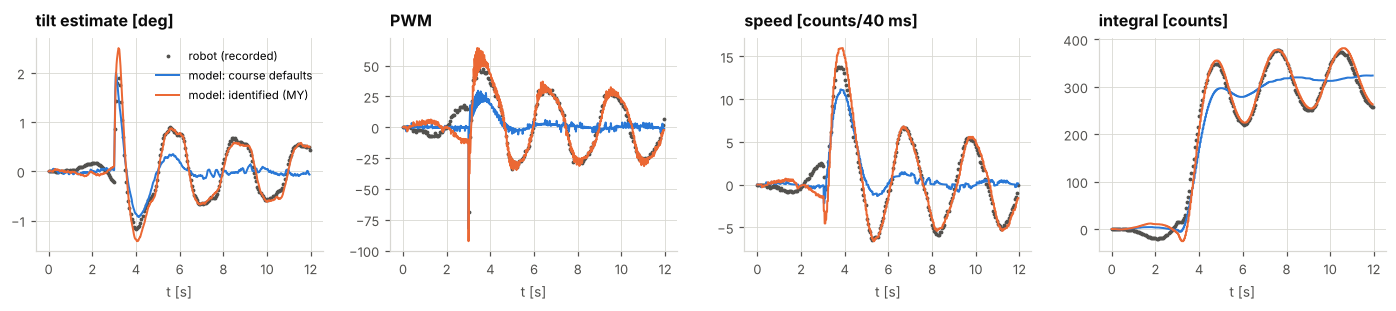

In [9]:
def compare(log_path, models, gains, dz=1.5):
    log = tb.load_log(log_path)
    t_step = log["events"][0][0]                     # the robot reported when the gain changed
    fig, axs = plt.subplots(1, 4, figsize=(13, 2.9))
    cols = [("angle", "angle_est", "tilt estimate [deg]"), ("pwm", "u", "PWM"),
            ("speed", "speed_filter", "speed [counts/40 ms]"), ("integral", "integral", "integral [counts]")]
    for ax, (lc, _, lab) in zip(axs, cols):
        ax.plot(log["t"], log[lc], ".", ms=3, color=INK2, label="robot (recorded)")
        tidy(ax, lab, "t [s]")
    for (name, q), col in zip(models.items(), SERIES):
        sim = tb.simulate(q, gains, theta0_deg=0, t_end=log["t"][-1],
                          angle_zero=lambda t: dz if t >= t_step else 0.0)
        for ax, (_, sc, _) in zip(axs, cols):
            ax.plot(sim.t, getattr(sim, sc), color=col, lw=1.3, label=name)
    axs[0].legend(fontsize=7.5)
    plt.tight_layout(); plt.show()

compare("data/zstep.csv", {"model: course defaults": p, "model: identified (MY)": MY}, g)

How to read such a comparison, and what to do about differences:

| what you see | likely cause | parameter to revisit |
|---|---|---|
| timing of the slow swing differs | speed-loop scaling | `counts_per_rev`, `r` |
| size of the PWM response differs | motor gain | `v_batt`, `stall_rated` |
| robot shows a steady rocking, model does not | gearbox friction, backlash | `tau_coulomb` (backlash is not modelled) |
| fast wiggles differ | inertia split | `I_rotor`, `I_body`, `l` |
| model fine for small motions, off for big ones | saturation, tyre slip | — (limits of the model) |

In the synthetic example the identified model follows the recording closely and
the default one is visibly off. With a real robot expect agreement in shape and
time scale, not in every wiggle — that is enough for the simulation to answer
"which way should I move this gain, and roughly how far".

## 4.7 · Tuning on the hardware

### Before you start

- **Battery charged.** The firmware goes into low-voltage mode below 7.8 V and
  stops below 7.0 V; gains tuned on a nearly empty battery are too hot on a full one.
- Robot on the **floor**, on a surface with grip (not a table, not deep carpet).
- Keep a hand ready above the robot, not in front of the wheels. The motors cut
  out beyond ±22°, so a fall ends quietly — let it fall rather than grab the wheels.
- Hair, cables and fingers away from the wheels; they go from zero to full speed in 50 ms.
- Change **one** gain at a time, by about 20 %, and write down what you did.
  Record a log for every setting worth remembering.
- Stock values (`P55 D0.75 S10 I0.26`) are your known-good fallback. A reset restores them.

### Procedure

The order of notebook 3.8, with what to type and what to look at.

**Step 0 — sensors.** `T1`. Robot lying still: `gyro` ≈ 0 (else set
`angular_velocity_zero`). Robot held at its balance point: note `angle`, send `Z<that value>`.

**Step 1 — balance stiffness.** `S0`, `I0` (speed loop off; the robot will now
drift, so stay with it). Start low, `P20`, and hold the robot loosely upright:
it should push weakly against a tilt. Raise in steps (`P30`, `P40`, …). You are
looking for the value where it stands firmly against your fingertip, and for
the higher value where it starts to buzz or twitch. Choose about 60 % of the
buzzing value. Without the speed loop it will not stay in place — that is expected (notebook 2.2).

**Step 2 — damping.** Raise `D` from 0 in steps of 0.25. In the model the
visible effect is small (the motors damp already); on the robot it may calm a
fast ringing or a twitch that comes from gear backlash.
Stop when you hear the motors growl or see `pwm` in the log become noisy; go back one step.

**Step 3 — speed loop.** `S3`, then up in steps of 1–2. Nudge the robot each
time. Too low: it rolls away and falls. Right: it rolls a hand's width, stops,
and stays roughly there. Too high: a nudge makes it whip back and tip. If it
whips before it ever stops rolling away, `kp_balance` is too low for this
`kp_speed` (the wedge in notebook 3.4) — raise `P` by 20 % and try again.

**Step 4 — integral.** `I0.05`, then up. It should now return to where it
started. Too high: slow rocking back and forth that does not die out. Remember
that with the real tilt estimator the usable range of `ki_speed` is smaller
than the stability map suggests (notebook 3.5).

**Step 5 — verify.** Push test (gentle → firm). Zero-angle step with a log.
Drive forward and stop. Then repeat the push test with the battery at ~7.4 V.
Compare the log with `tb.simulate(MY, your_gains, ...)`.

**Step 6 — make it permanent.** Type the gains into `BalanceCar.h`
(`kp_balance`, `kd_balance`, `kp_speed`, `ki_speed`, `angle_zero`) and upload.

Before each hardware session it takes a minute to ask the simulation where the
edges are for *your* robot:

In [10]:
def edges(q, g0, name, lo, hi, n=120):
    vals = np.linspace(lo, hi, n)
    ok = np.array([tb.stability_margin(q, g0.with_(**{name: v})) < 1 for v in vals])
    if not ok.any():
        return "no stable value in range"
    return f"stable from {vals[ok][0]:6.2f} to {vals[ok][-1]:6.2f}" + ("+" if ok[-1] else " ")

print("Model prediction for MY robot, other gains at stock (perfect sensors, small motions):")
for name, lo, hi in [("kp_balance", 1, 400), ("kd_balance", 0, 15), ("kp_speed", 0, 40), ("ki_speed", 0, 3)]:
    print(f"   {name:11s} {edges(MY, g, name, lo, hi)}     stock = {getattr(g, name)}")

Model prediction for MY robot, other gains at stock (perfect sensors, small motions):
   kp_balance  stable from  31.18 to 400.00+     stock = 55.0
   kd_balance  stable from   0.00 to  12.23      stock = 0.75
   kp_speed    stable from   3.36 to  18.49      stock = 10.0
   ki_speed    stable from   0.03 to   1.84      stock = 0.26


Treat these as a map of where the cliffs are, not as targets: real margins are
smaller (estimator, backlash, friction), so stay well inside.

### Troubleshooting

| symptom | most likely cause | what to do |
|---|---|---|
| does nothing after switch-on, red LEDs | battery low, or tilted beyond ±22° at start | charge; hold upright during the first 2 s |
| drives off immediately in one direction and falls | motor or encoder polarity, or `angle_zero` far off | check `angle` reads ≈ 0 upright; check that tilting forward gives positive `pwm` and wheels turning forward |
| falls over slowly, feels soft | `kp_balance` too low, or battery low | raise `P`; check voltage |
| fast buzz / hard twitching (10 Hz and up) | `kp_balance` or `kd_balance` too high; loose parts; backlash | lower `P` by 20 %, then `D`; tighten screws and wheel hubs |
| slow rocking on the spot (period of seconds), constant size | gearbox friction limit cycle | normal to a degree; a little more `P` or less `I` shrinks it |
| slow rocking that grows | `ki_speed` too high | lower `I` |
| rolls away steadily | `kp_speed` too low, or `ki_speed` = 0 with a wrong `angle_zero` | raise `S`; set `Z`; add `I` |
| a nudge makes it whip back and tip | `kp_speed` too high for this `kp_balance` | lower `S` or raise `P` |
| fine at first, worse after minutes | battery sagging; motors warm | re-check at lower voltage, keep margin |
| good when free, bad with USB cable | cable pulling | lighter cable, or log over Bluetooth |
| jittery since you added code | something slow in the 5 ms interrupt, or long `Serial.print` | keep `balanceCar()` lean; print only from `loop()` |

## 4.8 · Where to go from here

- **Write the balance firmware yourself**, from an empty sketch: read the MPU-6050,
  a complementary filter in five lines, PD, then the speed loop. With
  `Motor_Step_Test.ino` you have already seen the motor, encoder and interrupt parts.
  `tb.FirmwareController` is a reference you can test your logic against, line by line.
- **Use both encoder channels** if the connector exposes channel B: real direction,
  twice the resolution, and the speed-sign guess disappears.
- **Estimate speed better** (e.g. from the model plus encoder, in a small
  observer) and try the state-feedback controller of notebook 2.8 on the robot.
- **Turning**: the third loop (`kp_turn`, `kd_turn`) is a clean little PD
  exercise of its own, decoupled from balancing.

## Exercises

1. Run E1 and E5 on your robot and build `MY`. How far is the stock-gain
   stability measure from the course default?
2. Record a zero-angle step and overlay it with `compare(...)`. Which row of the
   mismatch table applies?
3. In `Tuning.h`, add a command `K` that prints the battery voltage (the formula
   is in `voltage.h`). Then log it during a long run.
4. Predict with `tb.simulate(MY, ...)` what `P80` does to the zero-angle step,
   then try it on the robot. Was the direction of the change right? The size?